# Fake News Classification with WELFake Dataset
## Clean workflow: TF-IDF baseline + LSTM + Dropout LSTM + Bidirectional LSTM

This notebook is adapted for the WELFake dataset, which commonly contains `title`, `text`, and `label` (sometimes also an index column). The fewer columns are fine: title and article text are enough to build text-classification models.

**Label convention used here:** WELFake commonly uses `1 = fake` and `0 = real`. Cell 3 prints the label counts and makes this mapping explicit. Verify the dataset's documentation or source before interpreting the final metrics.

The notebook uses one stratified 70% / 15% / 15% train-validation-test split. The tokenizer and TF-IDF vectorizer are fitted on training data only. Validation data is used for model selection/early stopping; the test set is reserved for final evaluation.

## Cell 1 — Import libraries and set reproducibility

In [4]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Cell 2 — Load the WELFake CSV

In [5]:
import os
import csv
import sys
import pandas as pd

DATA_PATH = "/content/WELFake_Dataset.csv"

# Allow very large article-text fields
csv.field_size_limit(sys.maxsize)

print("File exists:", os.path.exists(DATA_PATH))

# Load CSV with the correct header and large-field support
news_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8",
    engine="python",
    on_bad_lines="error"
)

# Remove the saved DataFrame index column, if present
news_raw = news_raw.loc[
    :, ~news_raw.columns.astype(str).str.match(r"^Unnamed:")
]

print("\nDataset shape:", news_raw.shape)
print("Columns:", news_raw.columns.tolist())

print("\nMissing values:")
display(news_raw.isnull().sum().to_frame("missing_count"))

print("\nLabel distribution:")
print(news_raw["label"].value_counts(dropna=False))

display(news_raw.head())

File exists: True

Dataset shape: (72134, 3)
Columns: ['title', 'text', 'label']

Missing values:


,missing_count
title,558
text,39
label,0



Label distribution:
label
1    37106
0    35028
Name: count, dtype: int64


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


## Cell 3 — Validate columns and inspect labels

In [6]:
required_columns = {"title", "text", "label"}
missing_columns = required_columns - set(news_raw.columns)

if missing_columns:
    raise ValueError(
        f"Required columns missing: {sorted(missing_columns)}. "
        f"Available columns: {news_raw.columns.tolist()}"
    )

print("Missing values:")
display(news_raw[["title", "text", "label"]].isnull().sum().to_frame("missing_count"))

print("\nRaw label values and counts:")
print(news_raw["label"].value_counts(dropna=False))

# WELFake's commonly used convention is: 1 = fake, 0 = real.
# If your specific file's documentation says otherwise, change this mapping.
LABEL_MAP = {
    0: 0,       # real -> 0 (target encoding)
    1: 1,       # fake -> 1 (target encoding)
    "0": 0,
    "1": 1,
    "real": 0,
    "fake": 1
}

news = news_raw.copy()
normalized_label = news["label"].astype(str).str.strip().str.lower()
news["label_bin"] = normalized_label.map(LABEL_MAP)

unknown = sorted(normalized_label[news["label_bin"].isna()].unique().tolist())
if unknown:
    raise ValueError(
        f"Unrecognized labels: {unknown}. Update LABEL_MAP after checking the dataset."
    )

news["label_bin"] = news["label_bin"].astype("int32")
news["title"] = news["title"].fillna("").astype(str)
news["text"] = news["text"].fillna("").astype(str)

print("\nEncoded target meaning: 0 = real, 1 = fake")
print(news["label_bin"].value_counts().rename(index={0: "real (0)", 1: "fake (1)"}))
print("\nTarget proportions:")
print(news["label_bin"].value_counts(normalize=True).sort_index().round(3))

Missing values:


,missing_count
title,558
text,39
label,0



Raw label values and counts:
label
1    37106
0    35028
Name: count, dtype: int64

Encoded target meaning: 0 = real, 1 = fake
label_bin
fake (1)    37106
real (0)    35028
Name: count, dtype: int64

Target proportions:
label_bin
0    0.486
1    0.514
Name: proportion, dtype: float64


## Cell 4 — Prepare text and check duplicates

In [7]:
# Use title + body. Missing title is allowed; missing body becomes an empty string.
news["combined_text"] = (
    news["title"].str.strip() + " " + news["text"].str.strip()
).str.strip()

# Remove rows with no usable title or article text.
news = news[news["combined_text"].str.len() > 0].copy()

# Find identical text records that have conflicting labels.
label_counts_per_text = news.groupby("combined_text")["label_bin"].nunique()
conflicting_texts = label_counts_per_text[label_counts_per_text > 1].index

print("Unique text groups with conflicting labels:", len(conflicting_texts))
if len(conflicting_texts) > 0:
    print("Removing groups where the same text has conflicting labels.")
    news = news[~news["combined_text"].isin(conflicting_texts)].copy()

duplicate_count = news.duplicated(subset=["combined_text"]).sum()
print("Duplicate combined-text rows:", duplicate_count)

news = news.drop_duplicates(subset=["combined_text"], keep="first").reset_index(drop=True)

print("Dataset shape after text/duplicate handling:", news.shape)
print("\nLabel distribution after cleaning:")
print(news["label_bin"].value_counts().rename(index={0: "real (0)", 1: "fake (1)"}))

Unique text groups with conflicting labels: 0
Duplicate combined-text rows: 8458
Dataset shape after text/duplicate handling: (63676, 5)

Label distribution after cleaning:
label_bin
real (0)    34790
fake (1)    28886
Name: count, dtype: int64


## Cell 5 — Inspect random examples

In [8]:
# Manually check whether articles are coherent and whether labels match the source's convention.
sample_df = news.sample(n=min(12, len(news)), random_state=SEED)

for i, row in enumerate(sample_df.itertuples(index=False), start=1):
    print(f"--- Sample {i} | label={row.label_bin} ({'FAKE' if row.label_bin == 1 else 'REAL'}) ---")
    print("Title:", row.title[:300])
    print("Text excerpt:", row.text[:600])
    print("-" * 90)

--- Sample 1 | label=1 (FAKE) ---
Title: PHILIPPINES: 2016 Washington’s Fury as Philippine’s Elections Threaten US Anti-China Policy
Text excerpt:  Duterte takes clear lead in Philippine elections. (Photo: IBT)Andrew Korybko The DuranMay 2016: As Filipinos choose their next President on Monday, prospect of election of anti-establishment candidate threatens the geopolitical viability of the US s Pivot to Asia.The Philippines votes for its next President on Monday.  Whilst the rest of the world pays little attention, strategists in Washington are worried.The electoral frontrunner is Rodrigo Duterte, an eccentric, no-nonsense former mayor from the southern island of Mindanao who commands a Trump-like popularity and an equally loyal followin
------------------------------------------------------------------------------------------
--- Sample 2 | label=0 (REAL) ---
Title: Hillary Clinton wins debate, Bernie Sanders rises in polls
Text excerpt: Washington (CNN) With the first Democratic deba

## Cell 6 — Create stratified train / validation / test splits

In [9]:
X = news["combined_text"]
y = news["label_bin"]

# 70% train, 30% temporary set.
x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Split the temporary set equally: 15% validation, 15% test.
x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Train:      {len(x_train_raw):,} ({len(x_train_raw)/len(news):.1%})")
print(f"Validation: {len(x_val_raw):,} ({len(x_val_raw)/len(news):.1%})")
print(f"Test:       {len(x_test_raw):,} ({len(x_test_raw)/len(news):.1%})")

print("\nClass proportions (0=real, 1=fake):")
for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, labels.value_counts(normalize=True).sort_index().round(3).to_dict())

Train:      44,573 (70.0%)
Validation: 9,551 (15.0%)
Test:       9,552 (15.0%)

Class proportions (0=real, 1=fake):
train {0: 0.546, 1: 0.454}
validation {0: 0.546, 1: 0.454}
test {0: 0.546, 1: 0.454}


## Cell 7 — Baseline: TF-IDF + Logistic Regression

In [10]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(x_train_raw)
X_val_tfidf = tfidf.transform(x_val_raw)
X_test_tfidf = tfidf.transform(x_test_raw)

baseline_lr = LogisticRegression(
    max_iter=2000,
    C=1.0,
    random_state=SEED
)
baseline_lr.fit(X_train_tfidf, y_train)

val_pred_lr = baseline_lr.predict(X_val_tfidf)
test_pred_lr = baseline_lr.predict(X_test_tfidf)

print("TF-IDF + Logistic Regression")
print(f"Validation accuracy: {accuracy_score(y_val, val_pred_lr):.4f}")
print(f"Test accuracy:       {accuracy_score(y_test, test_pred_lr):.4f}")
print("\nTest classification report (0=real, 1=fake):")
print(classification_report(
    y_test, test_pred_lr,
    labels=[0, 1],
    target_names=["real (0)", "fake (1)"],
    zero_division=0
))
print("Test confusion matrix (rows=actual, columns=predicted; order 0,1):")
print(confusion_matrix(y_test, test_pred_lr, labels=[0, 1]))

TF-IDF + Logistic Regression
Validation accuracy: 0.9597
Test accuracy:       0.9580

Test classification report (0=real, 1=fake):
              precision    recall  f1-score   support

    real (0)       0.96      0.96      0.96      5219
    fake (1)       0.95      0.96      0.95      4333

    accuracy                           0.96      9552
   macro avg       0.96      0.96      0.96      9552
weighted avg       0.96      0.96      0.96      9552

Test confusion matrix (rows=actual, columns=predicted; order 0,1):
[[5006  213]
 [ 188 4145]]


## Cell 8 — Light cleaning and training-only tokenization

In [11]:
def clean_text(text):
    # Keep word order and negation words. Avoid stopword removal and stemming at first.
    text = re.sub(r"[^a-zA-Z\s]", " ", str(text))
    text = re.sub(r"\s+", " ", text)
    return text.lower().strip()

x_train_clean = x_train_raw.apply(clean_text).tolist()
x_val_clean = x_val_raw.apply(clean_text).tolist()
x_test_clean = x_test_raw.apply(clean_text).tolist()

VOCAB_SIZE = 20000
MAX_LEN = 300
EMBEDDING_DIM = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(x_train_clean)  # Fit on train only to avoid leakage.

train_seq = tokenizer.texts_to_sequences(x_train_clean)
val_seq = tokenizer.texts_to_sequences(x_val_clean)
test_seq = tokenizer.texts_to_sequences(x_test_clean)

x_train_pad = pad_sequences(train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
x_val_pad = pad_sequences(val_seq, maxlen=MAX_LEN, padding="post", truncating="post")
x_test_pad = pad_sequences(test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("Vocabulary size configured:", VOCAB_SIZE)
print("Train sequences:", x_train_pad.shape)
print("Validation sequences:", x_val_pad.shape)
print("Test sequences:", x_test_pad.shape)

Vocabulary size configured: 20000
Train sequences: (44573, 300)
Validation sequences: (9551, 300)
Test sequences: (9552, 300)


## Cell 9 — Model builder and evaluation helper

In [12]:
def build_lstm_model(kind="standard"):
    model = Sequential()
    model.add(Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ))

    if kind == "standard":
        model.add(LSTM(64))
    elif kind == "dropout":
        model.add(Dropout(0.25))
        model.add(LSTM(64, dropout=0.2))
        model.add(Dropout(0.25))
    elif kind == "bidirectional":
        model.add(Dropout(0.25))
        model.add(Bidirectional(LSTM(64, dropout=0.2)))
        model.add(Dropout(0.25))
    else:
        raise ValueError("kind must be 'standard', 'dropout', or 'bidirectional'")

    model.add(Dense(1, activation="sigmoid"))
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def get_metrics(model, x, y_true):
    probabilities = model.predict(x, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype("int32")
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0)
    }

def print_test_report(model, x, y_true, model_name):
    probabilities = model.predict(x, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype("int32")

    print(f"\n=== {model_name} — TEST SET ===")
    print(f"Accuracy: {accuracy_score(y_true, predictions):.4f}")
    print(f"Precision: {precision_score(y_true, predictions, zero_division=0):.4f}")
    print(f"Recall: {recall_score(y_true, predictions, zero_division=0):.4f}")
    print(f"F1-score: {f1_score(y_true, predictions, zero_division=0):.4f}")
    print("\nConfusion matrix (rows=actual, columns=predicted; 0=real, 1=fake):")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))
    print("\nClassification report:")
    print(classification_report(
        y_true, predictions,
        labels=[0, 1],
        target_names=["real (0)", "fake (1)"],
        zero_division=0
    ))

## Cell 10 — Train Standard LSTM

In [13]:
early_stop_standard = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_lstm = build_lstm_model("standard")
history_lstm = model_lstm.fit(
    x_train_pad, y_train_np,
    validation_data=(x_val_pad, y_val_np),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop_standard],
    verbose=1
)

Epoch 1/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 118s 167ms/step - accuracy: 0.8333 - loss: 0.4046 - val_accuracy: 0.7917 - val_loss: 0.4098
Epoch 2/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 116s 166ms/step - accuracy: 0.8141 - loss: 0.4240 - val_accuracy: 0.7082 - val_loss: 0.5503
Epoch 3/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 143s 167ms/step - accuracy: 0.8165 - loss: 0.4248 - val_accuracy: 0.8177 - val_loss: 0.4528
Epoch 4/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 116s 166ms/step - accuracy: 0.8655 - loss: 0.3233 - val_accuracy: 0.8864 - val_loss: 0.3048
Epoch 5/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 116s 166ms/step - accuracy: 0.9174 - loss: 0.2220 - val_accuracy: 0.8933 - val_loss: 0.2960
Epoch 6/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 117s 168ms/step - accuracy: 0.9119 - loss: 0.2387 - val_accuracy: 0.8867 - val_loss: 0.3328
Epoch 7/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 141s 167ms/step - accuracy: 0.8367 - loss: 0.3650 - val_accuracy: 0.7665 - val_loss: 0.4911
Epoch 8/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 124s 179ms/step - accuracy: 0.9080 -

## Cell 11 — Train LSTM with Dropout

In [14]:
early_stop_dropout = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_dropout = build_lstm_model("dropout")
history_dropout = model_dropout.fit(
    x_train_pad, y_train_np,
    validation_data=(x_val_pad, y_val_np),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop_dropout],
    verbose=1
)

Epoch 1/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 136s 191ms/step - accuracy: 0.7753 - loss: 0.4818 - val_accuracy: 0.7581 - val_loss: 0.4958
Epoch 2/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 140s 189ms/step - accuracy: 0.8364 - loss: 0.3929 - val_accuracy: 0.8551 - val_loss: 0.3846
Epoch 3/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 127s 182ms/step - accuracy: 0.8793 - loss: 0.3044 - val_accuracy: 0.8724 - val_loss: 0.3259
Epoch 4/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 131s 188ms/step - accuracy: 0.8251 - loss: 0.3842 - val_accuracy: 0.7466 - val_loss: 0.5201
Epoch 5/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 127s 182ms/step - accuracy: 0.8246 - loss: 0.3802 - val_accuracy: 0.8463 - val_loss: 0.3423
Epoch 6/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 127s 182ms/step - accuracy: 0.8550 - loss: 0.3374 - val_accuracy: 0.8062 - val_loss: 0.4092


## Cell 12 — Train Bidirectional LSTM

In [15]:
early_stop_bi = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_bilstm = build_lstm_model("bidirectional")
history_bilstm = model_bilstm.fit(
    x_train_pad, y_train_np,
    validation_data=(x_val_pad, y_val_np),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop_bi],
    verbose=1
)

Epoch 1/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 226s 320ms/step - accuracy: 0.9287 - loss: 0.1701 - val_accuracy: 0.9600 - val_loss: 0.1073
Epoch 2/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 262s 320ms/step - accuracy: 0.9731 - loss: 0.0748 - val_accuracy: 0.9572 - val_loss: 0.1201
Epoch 3/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 232s 332ms/step - accuracy: 0.9864 - loss: 0.0416 - val_accuracy: 0.9541 - val_loss: 0.1443
Epoch 4/10
697/697 ━━━━━━━━━━━━━━━━━━━━ 253s 319ms/step - accuracy: 0.9919 - loss: 0.0238 - val_accuracy: 0.9563 - val_loss: 0.1484


## Cell 13 — Compare models using validation F1

In [16]:
models = {
    "Standard LSTM": model_lstm,
    "LSTM with Dropout": model_dropout,
    "Bidirectional LSTM": model_bilstm
}

validation_results = pd.DataFrame({
    name: get_metrics(model, x_val_pad, y_val_np)
    for name, model in models.items()
}).T.sort_values("F1", ascending=False)

display(validation_results)

best_model_name = validation_results.index[0]
best_model = models[best_model_name]
print("Best model selected using validation F1:", best_model_name)

,Accuracy,Precision,Recall,F1
Bidirectional LSTM,0.960004,0.950103,0.962382,0.956203
Standard LSTM,0.918857,0.946312,0.870529,0.906840
LSTM with Dropout,0.872369,0.848011,0.875606,0.861587


Best model selected using validation F1: Bidirectional LSTM


## Cell 14 — Final test evaluation

In [17]:
# The test set is used here for final evaluation, not for tuning.
print_test_report(best_model, x_test_pad, y_test_np, best_model_name)

print("\nTF-IDF Logistic Regression test accuracy:",
      round(accuracy_score(y_test, test_pred_lr), 4))


=== Bidirectional LSTM — TEST SET ===
Accuracy: 0.9577
Precision: 0.9480
Recall: 0.9594
F1-score: 0.9537

Confusion matrix (rows=actual, columns=predicted; 0=real, 1=fake):
[[4991  228]
 [ 176 4157]]

Classification report:
              precision    recall  f1-score   support

    real (0)       0.97      0.96      0.96      5219
    fake (1)       0.95      0.96      0.95      4333

    accuracy                           0.96      9552
   macro avg       0.96      0.96      0.96      9552
weighted avg       0.96      0.96      0.96      9552


TF-IDF Logistic Regression test accuracy: 0.958


## Cell 15 — Plot training and validation loss

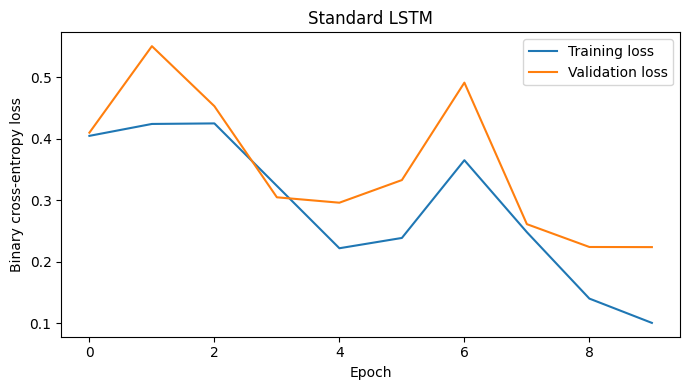

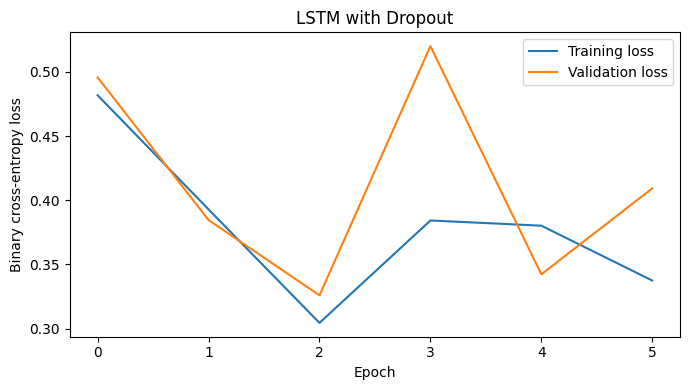

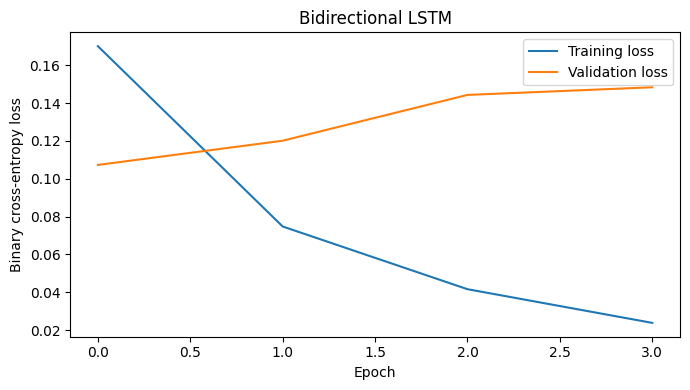

In [18]:
def plot_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(history_lstm, "Standard LSTM")
plot_history(history_dropout, "LSTM with Dropout")
plot_history(history_bilstm, "Bidirectional LSTM")

## Cell 16 — Save the selected model and tokenizer (optional)

In [19]:
# Run this cell only if you want to save artifacts for later inference.
import pickle

best_model.save("welfake_best_lstm.keras")

with open("welfake_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Saved: welfake_best_lstm.keras and welfake_tokenizer.pkl")

Saved: welfake_best_lstm.keras and welfake_tokenizer.pkl


## How to interpret results

- The WELFake dataset has only a few core columns; that is sufficient. The main inputs are `title` and `text`; `label` is the target.
- This notebook encodes **real = 0** and **fake = 1**, based on the commonly used WELFake convention. Verify against the exact source/version you downloaded.
- Compare TF-IDF and LSTM results on the same held-out test split.
- If training accuracy rises much higher than validation accuracy, the neural model is overfitting.
- If all models perform poorly, inspect the label convention, article quality, duplicate handling, preprocessing, and dataset version before making the architecture more complex.
- For a research report, document the dataset source, exact split, random seed, preprocessing, metrics, and limitations.